# Actividad calificable · Corte 3 — Análisis temporal y visualización

**Caso:** Spotify — capacidad de streaming y curaduría regional · **Autor:** Julián Andrés Solano Ledesma

Serie: visitas diarias al artículo *Spotify* de Wikipedia en inglés (API de Wikimedia, Semana 11). Tabla de eventos para la optimización SQL: la de la Semana 14. El cuaderno debe ejecutarse desde esta carpeta del repositorio.

## 1. Serie temporal: carga, `resample` y media móvil

In [1]:
import sqlite3, statistics, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd().parents[2]
sys.path[:0] = [str(RAIZ / "11-week" / "02-optional-activity"), str(RAIZ / "14-week" / "02-optional-activity")]
import serie_tiempo_spotify as S11   # carga, mensual(), media_movil_centrada(), indice_estacional()
import optimizacion_sql as O14       # genera la tabla de 2 millones de eventos
%matplotlib inline

Path("img").mkdir(exist_ok=True)
Path("datos").mkdir(exist_ok=True)
diaria = S11.extraer(usar_cache=True)
print(type(diaria.index).__name__, "·", len(diaria), "días ·", diaria.index.min().date(), "a", diaria.index.max().date(),
      "· nulos:", int(diaria.isna().sum()))

DatetimeIndex · 3926 días · 2016-01-01 a 2026-09-30 · nulos: 0


In [2]:
# Agregación por mes con resample y media móvil centrada de 12 meses (2x12)
m = pd.DataFrame({"visitas_total": diaria.resample("MS").sum(),
                  "visitas_dia_prom": diaria.resample("MS").mean().round(1)})
m["media_movil_2x12"] = m["visitas_dia_prom"].rolling(12).mean().rolling(2).mean().shift(-6).round(1)
pico = m["media_movil_2x12"].idxmax()
print("Tendencia: primera", m["media_movil_2x12"].first_valid_index().date(), m["media_movil_2x12"].dropna().iloc[0],
      "· máximo", pico.date(), m.loc[pico, "media_movil_2x12"],
      "· última", m["media_movil_2x12"].last_valid_index().date(), m["media_movil_2x12"].dropna().iloc[-1])
m.tail(8)

Tendencia: primera 2016-07-01 3611.0 · máximo 2022-07-01 9730.1 · última 2026-03-01 3877.4


,visitas_total,visitas_dia_prom,media_movil_2x12
fecha,,,
2026-02-01,105667,3773.8,4012.9
2026-03-01,104094,3357.9,3877.4
2026-04-01,98144,3271.5,NaN
2026-05-01,153222,4942.6,NaN
2026-06-01,105693,3523.1,NaN
2026-07-01,95507,3080.9,NaN
2026-08-01,86993,2806.2,NaN
2026-09-01,74840,2494.7,NaN


In [3]:
# Estacionalidad: cociente de cada mes frente a su tendencia, mediana por mes de calendario
ratio = (m["visitas_dia_prom"] / m["media_movil_2x12"]).dropna()
indice = ratio.groupby(ratio.index.month).median()
indice = indice / indice.mean()
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
estacional = pd.DataFrame({"efecto_pct": ((indice - 1) * 100).round(1).values,
                           "años_sobre_tendencia": ratio.gt(1).groupby(ratio.index.month).sum().values,
                           "años_medidos": ratio.groupby(ratio.index.month).count().values}, index=MESES)
estacional

,efecto_pct,años_sobre_tendencia,años_medidos
ene,4.5,7,10
feb,5.4,7,10
mar,7.9,6,10
abr,8.7,6,9
may,-4.2,2,9
jun,-12.7,0,9
jul,-11.2,2,10
ago,-6.7,0,10
sep,-3.3,4,10
oct,-2.7,4,10


In [4]:
# Temporada alta (nov–abr) frente a baja (may–oct). La alta de 2023 va de nov 2022 a abr 2023.
d = diaria.to_frame("visitas")
d["alta"] = d.index.month.isin([11, 12, 1, 2, 3, 4])
d["temporada"] = d.index.year + (d.index.month >= 11).astype(int)
tempo = d.groupby(["temporada", "alta"])["visitas"].median().unstack().rename(columns={True: "alta", False: "baja"})[["alta", "baja"]]
tempo["alta_vs_baja_pct"] = ((tempo["alta"] / tempo["baja"] - 1) * 100).round(1)
gana = int((tempo["alta_vs_baja_pct"] >= 1).sum())     # diferencias de menos de 1 % se cuentan como empate
print(f"La temporada alta supera a la baja en {gana} de {len(tempo)} años; empates:", tempo.index[tempo["alta_vs_baja_pct"].abs() < 1].tolist())
tempo

La temporada alta supera a la baja en 8 de 11 años; empates: [2022]


alta,alta,baja,alta_vs_baja_pct
temporada,,,
2016,3519.0,3412.5,3.1
2017,4106.0,3718.5,10.4
2018,4214.0,3807.5,10.7
2019,4433.0,4029.5,10.0
2020,4790.5,5527.5,-13.3
2021,5979.0,6607.5,-9.5
2022,7431.0,7428.0,0.0
2023,9252.0,5555.0,66.6
2024,5285.5,4525.0,16.8


## 2. Visualizaciones

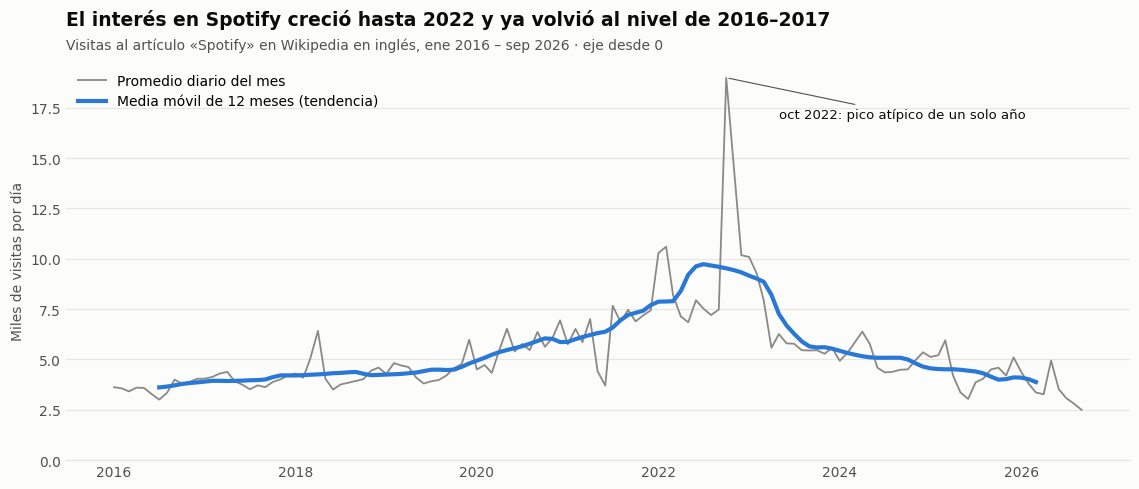

In [5]:
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"
TINTA, TINTA2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e7e6e2", "#fcfcfb"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "figure.facecolor": FONDO, "axes.facecolor": FONDO})

def limpiar(ax):
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(REJILLA)
    ax.tick_params(length=0, colors=TINTA2)
    ax.yaxis.grid(True, color=REJILLA)
    ax.set_axisbelow(True)

# Visualización 1 · evolución
fig, ax = plt.subplots(figsize=(11.5, 5))
ax.plot(m.index, m["visitas_dia_prom"] / 1000, color=GRIS, lw=1.3, label="Promedio diario del mes")
ax.plot(m.index, m["media_movil_2x12"] / 1000, color=AZUL, lw=3, label="Media móvil de 12 meses (tendencia)")
ax.set_ylim(0, None)
ax.set_ylabel("Miles de visitas por día", color=TINTA2)
oct22 = pd.Timestamp("2022-10-01")
ax.annotate("oct 2022: pico atípico de un solo año", xy=(oct22, m.loc[oct22, "visitas_dia_prom"] / 1000),
            xytext=(pd.Timestamp("2023-05-01"), 17), color=TINTA, fontsize=9.5, arrowprops=dict(arrowstyle="-", color=TINTA2, lw=0.8))
ax.legend(frameon=False, loc="upper left")
limpiar(ax)
ax.set_title("El interés en Spotify creció hasta 2022 y ya volvió al nivel de 2016–2017", loc="left", fontsize=13.5, fontweight="bold", color=TINTA, pad=26)
ax.text(0, 1.03, "Visitas al artículo «Spotify» en Wikipedia en inglés, ene 2016 – sep 2026 · eje desde 0", transform=ax.transAxes, color=TINTA2)
fig.tight_layout(); fig.savefig("img/evolucion-tendencia.png", dpi=140); plt.show()

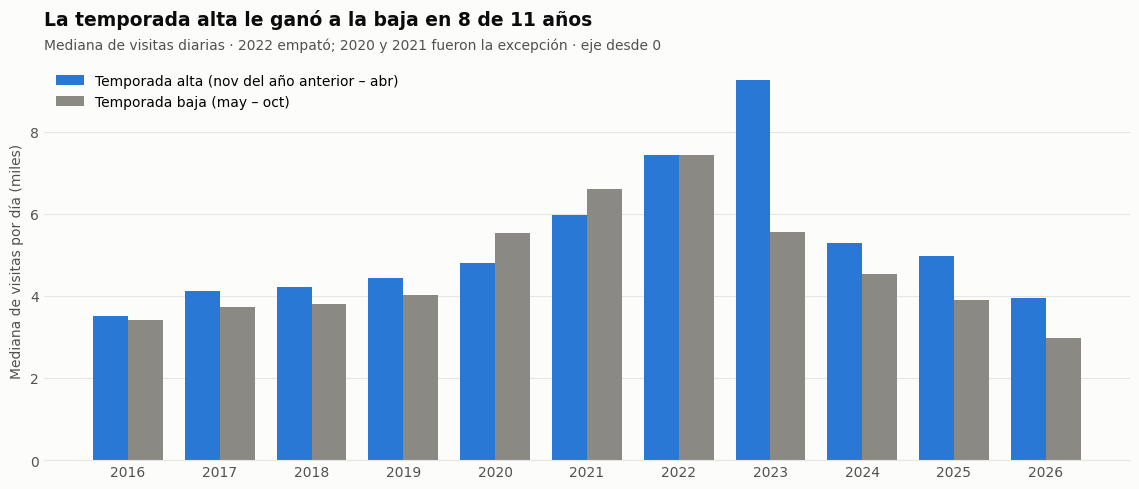

In [6]:
# Visualización 2 · comparación
fig, ax = plt.subplots(figsize=(11.5, 5))
x = range(len(tempo)); ancho = 0.38
ax.bar([i - ancho / 2 for i in x], tempo["alta"] / 1000, ancho, color=AZUL, label="Temporada alta (nov del año anterior – abr)")
ax.bar([i + ancho / 2 for i in x], tempo["baja"] / 1000, ancho, color=GRIS, label="Temporada baja (may – oct)")
ax.set_xticks(list(x), tempo.index)
ax.set_ylim(0, None)
ax.set_ylabel("Mediana de visitas por día (miles)", color=TINTA2)
ax.legend(frameon=False, loc="upper left")
limpiar(ax); ax.yaxis.grid(True, color=REJILLA)
ax.set_title(f"La temporada alta le ganó a la baja en {gana} de {len(tempo)} años", loc="left", fontsize=13.5, fontweight="bold", color=TINTA, pad=26)
ax.text(0, 1.03, "Mediana de visitas diarias · 2022 empató; 2020 y 2021 fueron la excepción · eje desde 0", transform=ax.transAxes, color=TINTA2)
fig.tight_layout(); fig.savefig("img/comparacion-temporadas.png", dpi=140); plt.show()

## 3. Optimización SQL: horas por mes en la temporada alta nov 2024 – abr 2025

In [7]:
if not O14.EVENTOS.exists():
    O14.generar_eventos()              # 2 000 000 de eventos, semilla fija, ~15 s
con = sqlite3.connect(O14.EVENTOS)

LENTA = '''SELECT * FROM reproduccion
WHERE  strftime('%Y-%m', fecha_hora) BETWEEN '2024-11' AND '2025-04' '''
RAPIDA = '''SELECT substr(fecha_hora, 1, 7) AS mes, ROUND(SUM(segundos_escuchados) / 3600.0, 1) AS horas
FROM   reproduccion
WHERE  fecha_hora >= '2024-11-01' AND fecha_hora < '2025-05-01'
GROUP  BY mes ORDER BY mes'''
SIMPLE = "CREATE INDEX idx_c3_fecha ON reproduccion (fecha_hora)"
CUBRE = "CREATE INDEX idx_c3_cubre ON reproduccion (fecha_hora, segundos_escuchados)"

def en_python(cur):
    cols = [c[0] for c in cur.description]; i_f, i_s = cols.index("fecha_hora"), cols.index("segundos_escuchados")
    filas = cur.fetchall(); suma = {}
    for f in filas:
        suma[f[i_f][:7]] = suma.get(f[i_f][:7], 0) + f[i_s]
    return [(k, round(v / 3600, 1)) for k, v in sorted(suma.items())], len(filas)

def medir(sql, indices, python=False, veces=5):
    for idx in ("idx_c3_fecha", "idx_c3_cubre", "idx_rep_fecha", "idx_rep_fecha_cubre"):
        con.execute(f"DROP INDEX IF EXISTS {idx}")
    for ddl in indices:
        con.execute(ddl)
    con.execute("ANALYZE")
    tiempos = []
    for _ in range(veces):
        t0 = time.perf_counter(); cur = con.execute(sql)
        res, filas = en_python(cur) if python else ((lambda r: (r, len(r)))(cur.fetchall()))
        tiempos.append(time.perf_counter() - t0)
    plan = " | ".join(p[3] for p in con.execute("EXPLAIN QUERY PLAN " + sql))
    return round(statistics.median(tiempos) * 1000, 1), filas, plan, res

casos = [("Antes: SELECT * + función en WHERE + suma en Python", LENTA, [], True),
         ("Rango y GROUP BY en SQL, sin índice", RAPIDA, [], False),
         ("Rango + índice simple (fecha_hora)", RAPIDA, [SIMPLE], False),
         ("Después: rango + índice de cobertura", RAPIDA, [CUBRE], False)]
filas = []; referencia = None
for nombre, sql, idx, py in casos:
    ms, n, plan, res = medir(sql, idx, py)
    referencia = referencia or res
    igual = all(a[0] == b[0] and abs(a[1] - b[1]) <= 0.1 for a, b in zip(referencia, res)) and len(res) == len(referencia)
    filas.append({"versión": nombre, "ms": ms, "filas_devueltas": n, "mismo_resultado": igual, "plan": plan})
medicion = pd.DataFrame(filas)
medicion["veces_mas_rapida"] = (medicion["ms"].iloc[0] / medicion["ms"]).round(1)
medicion.to_csv("datos/medicion-sql.csv", index=False)
print("Horas por mes:", referencia)
pd.set_option("display.max_colwidth", 70)
medicion

Horas por mes: [('2024-11', 4188.3), ('2024-12', 4329.3), ('2025-01', 4031.3), ('2025-02', 3851.8), ('2025-03', 4260.9), ('2025-04', 4062.4)]


,versión,ms,filas_devueltas,mismo_resultado,plan,veces_mas_rapida
0,Antes: SELECT * + función en WHERE + suma en Python,1753.8,524910,True,SCAN reproduccion,1.0
1,"Rango y GROUP BY en SQL, sin índice",558.4,6,True,SCAN reproduccion | USE TEMP B-TREE FOR GROUP BY,3.1
2,Rango + índice simple (fecha_hora),3410.2,6,True,SEARCH reproduccion USING INDEX idx_c3_fecha (fecha_hora>? AND fec...,0.5
3,Después: rango + índice de cobertura,281.2,6,True,SEARCH reproduccion USING COVERING INDEX idx_c3_cubre (fecha_hora>...,6.2


In [8]:
for idx in ("idx_c3_fecha", "idx_c3_cubre"):
    con.execute(f"DROP INDEX IF EXISTS {idx}")
con.close()